# 21 · Multivariate forecasting

Does a forecast preserve the meaning of every target? Generate three related series, compare their point forecasts side by side, then deliberately reverse the target labels. Finally compare regressions using all-target lags with regressions using only their own target.

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

from timegym import Forecast, GaussianAR1Forecaster, NaiveForecaster, Pipeline, Scenario
from timegym.diagnostics import evaluate_forecast
from timegym.mutations import mutate_forecast

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Construct three related targets

Only context and future timestamps enter the model. Points have shape `(H, D)`, quantiles `(H, D, Q)`, and joint paths `(S, H, D)`. Target names and column order are part of the forecast, not decorative labels.

In [2]:
scenario = Scenario(
    'ar1', context_length=240, horizon=18, n_targets=3, seed=2026,
    parameters={
        'mean': [0.0, 4.0, -2.0], 'phi': 0.75, 'sigma': [0.4, 0.9, 0.6],
        'correlation': [[1.0, 0.7, 0.2], [0.7, 1.0, 0.4], [0.2, 0.4, 1.0]],
    },
)
case = scenario.generate()
context, future_index = case.task.context, case.task.future_index
assert context.shape == (240, 3)
assert case.observed.shape == (18, 3)
assert context.index[-1] < future_index[0]
display(context.tail())
display(pd.Series({'context': context.shape, 'future': case.observed.shape,
                   'target order': case.task.target_names, 'forecast begins': future_index[0]}))

,y0,y1,y2
235,0.258723,4.459462,-1.352858
236,1.198116,5.208630,-1.913426
237,0.916173,4.064935,-1.976771
238,0.930056,5.457001,-1.613743
239,0.204591,4.130515,-2.379557


context                (240, 3)
future                  (18, 3)
target order       (y0, y1, y2)
forecast begins             240
dtype: object

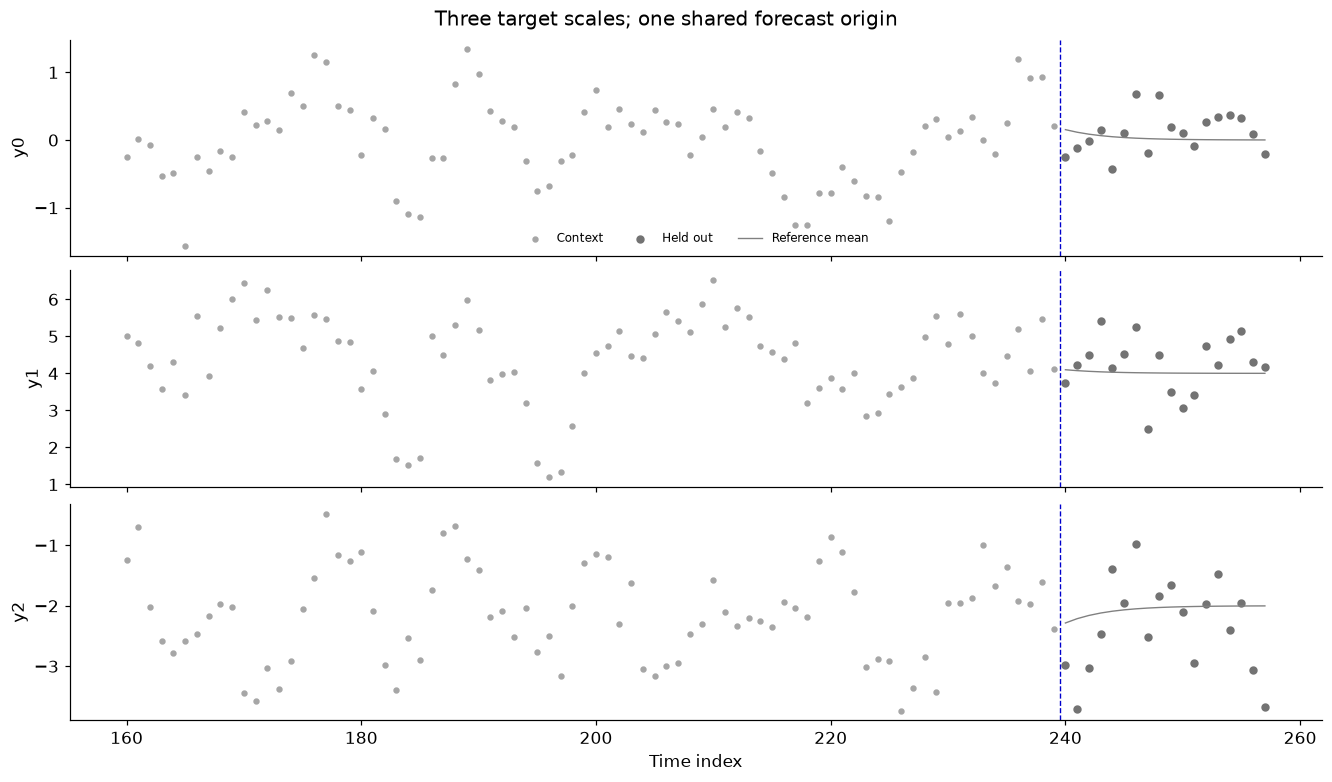

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, layout='constrained')
for d, (name, ax) in enumerate(zip(case.task.target_names, axes)):
    ax.scatter(context.index[-80:], context[name].iloc[-80:], color='0.65', s=10, label='Context')
    ax.scatter(future_index, case.observed[name], color='0.45', s=20, label='Held out')
    ax.plot(future_index, case.reference.mean[:, d], color='0.5', linewidth=0.9, label='Reference mean')
    ax.axvline(future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set_ylabel(name)
axes[0].legend(ncol=3, fontsize=8)
axes[-1].set_xlabel('Time index')
fig.suptitle('Three target scales; one shared forecast origin')
plt.show()

## Compare persistence with a fitted AR(1)

The AR(1) estimates one equation per target and paired innovation covariance from context. It preserves estimated cross-target dependence but has no cross-target lag coefficients: it is not a full VAR. The analytic reference knows the generator parameters and is the conditional expectation, not the realized noisy future.

In [4]:
naive_pipeline = Pipeline(NaiveForecaster(strategy='last'))
ar_pipeline = Pipeline(GaussianAR1Forecaster(n_samples=128, seed=610))
forecasts = {
    'Last value': naive_pipeline.predict(context, future_index),
    'Fitted AR(1)': ar_pipeline.predict(context, future_index),
    'Known conditional mean': Forecast(
        index=future_index.copy(), point=case.reference.mean.copy(),
        target_names=case.task.target_names,
    ),
}
ar_forecast = forecasts['Fitted AR(1)']
assert ar_forecast.validate(case.task) == []
assert ar_forecast.point.shape == (18, 3)
assert ar_forecast.samples.shape == (128, 18, 3)
assert ar_forecast.quantiles.shape == (18, 3, 3)
display(pd.Series({'points': ar_forecast.point.shape, 'quantiles': ar_forecast.quantiles.shape,
                   'joint samples': ar_forecast.samples.shape, 'quantile levels': ar_forecast.levels}))

points                     (18, 3)
quantiles               (18, 3, 3)
joint samples         (128, 18, 3)
quantile levels    (0.1, 0.5, 0.9)
dtype: object

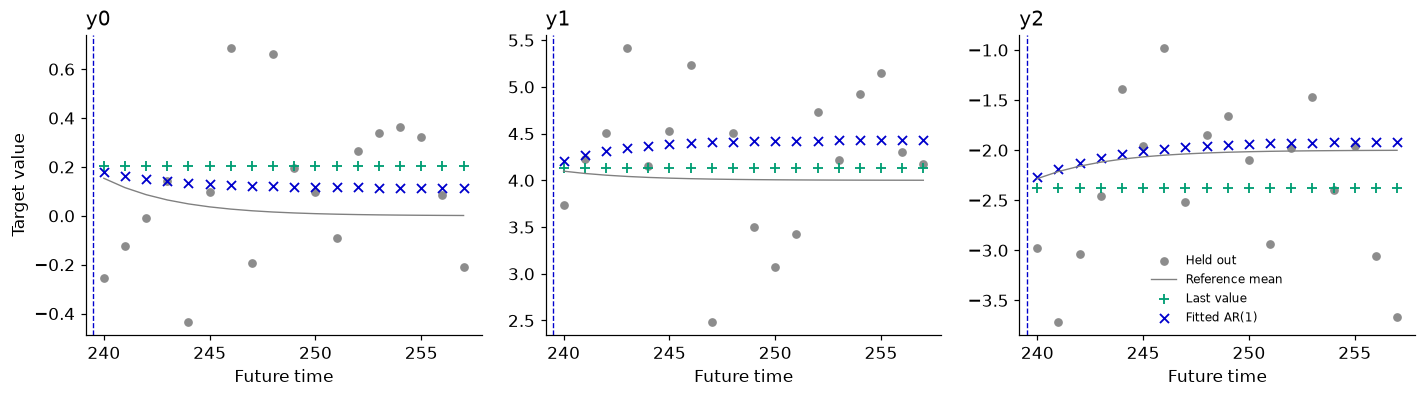

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
point_styles = {'Last value': ('#009E73', '+'), 'Fitted AR(1)': ('#0000CC', 'x')}
for d, (name, ax) in enumerate(zip(case.task.target_names, axes)):
    ax.scatter(future_index, case.observed[name], color='0.55', s=22, label='Held out')
    ax.plot(future_index, case.reference.mean[:, d], color='0.5', linewidth=0.9, label='Reference mean')
    for model_name, (color, marker) in point_styles.items():
        ax.scatter(future_index, forecasts[model_name].point[:, d], marker=marker, s=35,
                   color=color, linewidths=1.2, label=model_name)
    ax.axvline(future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
    ax.set(title=name, xlabel='Future time')
axes[0].set_ylabel('Target value')
axes[-1].legend(fontsize=8)
plt.show()

Read each column against its own gray observations and conditional mean. The AR(1) point crosses and persistence marks can trade places in realized accuracy; the reference minimizes expected squared loss, not the loss on every realized future.

## Which error are we measuring?

Realized-future MSE includes unpredictable innovations. Mean-reference MSE measures distance from the known conditional expectation; its reference row is zero by construction. Keep the targets separate because their scales differ. These one-case scores do not define a model ranking.

In [6]:
def per_target_scores(case, candidates):
    rows = []
    for model_name, forecast in candidates.items():
        assert forecast.validate(case.task) == []
        for d, target in enumerate(case.task.target_names):
            rows.append({
                'model': model_name, 'target': target,
                'realised_future_mse': np.mean((forecast.point[:, d] - case.observed.iloc[:, d].to_numpy()) ** 2),
                'mean_reference_mse': np.mean((forecast.point[:, d] - case.reference.mean[:, d]) ** 2),
            })
    return pd.DataFrame(rows).set_index(['model', 'target'])

point_scores = per_target_scores(case, forecasts)
display(point_scores.round(4))

realised_future_mse  mean_reference_mse
model                  target                                         
Last value             y0                   0.0958              0.0310
                       y1                   0.5686              0.0126
                       y2                   0.5659              0.1066
Fitted AR(1)           y0                   0.0919              0.0095
                       y1                   0.5828              0.1402
                       y2                   0.6373              0.0046
Known conditional mean y0                   0.1046              0.0000
                       y1                   0.6043              0.0000
                       y2                   0.6031              0.0000

## Give Ridge access to the other targets

Each Ridge regressor receives a flattened lag window containing all targets; separate fits receive only their own target. Scaling uses training windows only, and recursive prediction appends predictions, never held-out outcomes.

This generator's true conditional mean needs only each target's latest value. Correlated innovations alone do not create cross-lag effects, so extra inputs need not help.

In [7]:
window_length = 6
joint_ridge = (Pipeline(window_length=window_length)
               .add(StandardScaler()).add(Ridge(alpha=10.0)))
joint_forecast = joint_ridge.predict(context, future_index)

separate_points = []
for name in case.task.target_names:
    separate_pipeline = (Pipeline(window_length=window_length)
                         .add(StandardScaler()).add(Ridge(alpha=10.0)))
    one_target = separate_pipeline.predict(context[[name]], future_index)
    separate_points.append(one_target.point)
separate_forecast = Forecast(
    index=future_index.copy(), point=np.column_stack(separate_points),
    target_names=case.task.target_names,
)
ridge_forecasts = {'Ridge: all-target lags': joint_forecast, 'Ridge: own-target lags': separate_forecast}
assert joint_forecast.point.shape == separate_forecast.point.shape == (18, 3)
assert joint_forecast.validate(case.task) == separate_forecast.validate(case.task) == []
print(f'All-target regressor input: {window_length * context.shape[1]} features; '
      f'own-target regressor input: {window_length} features.')

All-target regressor input: 18 features; own-target regressor input: 6 features.


realised_future_mse  mean_reference_mse
model                  target                                         
Ridge: all-target lags y0                   0.0768              0.0098
                       y1                   0.6041              0.0993
                       y2                   0.7064              0.0293
Ridge: own-target lags y0                   0.0831              0.0070
                       y1                   0.5916              0.1475
                       y2                   0.6396              0.0103

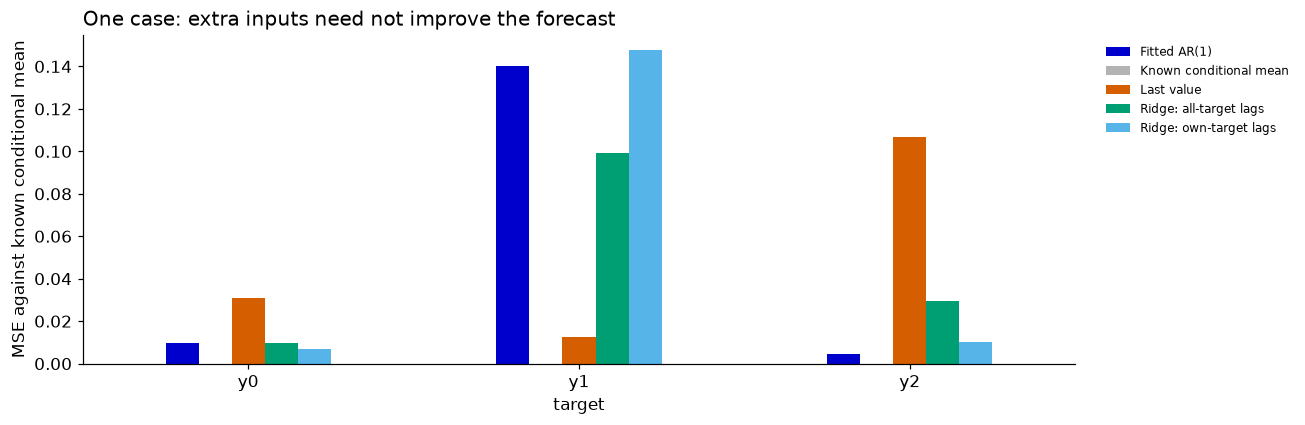

In [8]:
ridge_scores = per_target_scores(case, ridge_forecasts)
display(ridge_scores.round(4))
comparison = pd.concat([point_scores, ridge_scores])
plot_data = comparison['mean_reference_mse'].unstack('model')
error_colors = {'Fitted AR(1)': '#0000CC', 'Known conditional mean': '0.7',
                'Last value': '#D55E00', 'Ridge: all-target lags': '#009E73',
                'Ridge: own-target lags': '#56B4E9'}
ax = plot_data.plot.bar(figsize=(12, 4), rot=0, color=[error_colors[name] for name in plot_data.columns])
ax.set(ylabel='MSE against known conditional mean', title='One case: extra inputs need not improve the forecast')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

The all-target adapter can use the additional inputs, but this case does not establish a benefit from them. Test cross-lag capability on a generator containing cross-lag dynamics, and use independent replications before claiming a ranking. Continue with [capability sweeps](25_capability_sweeps.ipynb).

## Reverse the labels

`target_swap` changes declared target order while retaining the numeric arrays. The contract should reject that mismatch before scoring. The paired repair bypasses this explicit fixture; it does not automatically discover or fix arbitrary model code.

In [9]:
faulty = mutate_forecast(ar_forecast, 'target_swap')
repaired = mutate_forecast(ar_forecast, 'target_swap', enabled=False)
contract_rows = []
for state, forecast in [('clean', ar_forecast), ('swapped labels', faulty), ('repaired', repaired)]:
    result = evaluate_forecast(case, forecast)
    for diagnostic in result.diagnostics:
        if diagnostic.category == 'correctness':
            contract_rows.append({'state': state, 'check': diagnostic.name,
                                  'status': diagnostic.status, 'message': diagnostic.message})
display(pd.DataFrame(contract_rows))
assert any(item['code'] == 'target_mismatch' for item in faulty.validate(case.task))
assert repaired.validate(case.task) == []

,state,check,status,message
0,clean,forecast_contract,PASS,"Forecast indices, target order, shapes, finite..."
1,swapped labels,contract_target_mismatch,FAIL,Forecast targets or their order do not match t...
2,repaired,forecast_contract,PASS,"Forecast indices, target order, shapes, finite..."


A labeled shape can still hide a semantic error: swapping numbers while leaving labels unchanged needs a reference comparison or problem-specific check. Contract validity alone does not establish forecasting skill.

## Repeat the construction

Fixed scenario and model seeds should reproduce the arrays and alignment. This is a deterministic construction check, not a required statistical score.

In [10]:
repeat_case = scenario.generate()
repeat_forecast = ar_pipeline.predict(repeat_case.task.context, repeat_case.task.future_index)
pd.testing.assert_frame_equal(context, repeat_case.task.context)
pd.testing.assert_frame_equal(case.observed, repeat_case.observed)
np.testing.assert_array_equal(ar_forecast.point, repeat_forecast.point)
np.testing.assert_array_equal(ar_forecast.samples, repeat_forecast.samples)
assert repeat_forecast.index.equals(future_index)
print('Repeated scenario and fitted forecast match; index and target contracts hold.')

Repeated scenario and fitted forecast match; index and target contracts hold.


## Extend the example

Try different target scales, innovation correlations, and lag windows while keeping the forecast columns aligned. The fitted AR(1) ignores parameter uncertainty; the privileged reference is not an attainable real-data baseline. A single case cannot establish VAR capability or real-data transfer.

For distributions rather than points, continue with [univariate uncertainty](20_univariate_uncertainty.ipynb) and [multivariate uncertainty](22_multivariate_uncertainty.ipynb).